# SafeStep · 3 — Classical ML: train → validate → test (window + streaming)
`8 models × 2 tasks` · `3 feature sets` · `threshold tuned on validation` · `one final test` · `streaming test like a live phone`

Every fitted model is cached in Drive — if the runtime disconnects, re-run and it continues.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, json, time, warnings
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score, recall_score,
                             balanced_accuracy_score, confusion_matrix, classification_report,
                             precision_recall_curve, roc_curve)
warnings.filterwarnings('ignore')

BASE = '/content/drive/MyDrive/Daffodil Robo Tech Olympiad'
PROJ = f'{BASE}/SafeStep'
D = {k: f'{PROJ}/{k}' for k in ['data', 'artifacts', 'figures', 'models', 'code']}
MODEL_DIR = f"{D['models']}/classical"; os.makedirs(MODEL_DIR, exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
def save_fig(name): plt.savefig(f"{D['figures']}/{name}.png", dpi=300, bbox_inches='tight')

F    = pd.read_parquet(f"{D['data']}/features_345.parquet").set_index('win_id')
wm   = pd.read_parquet(f"{D['data']}/windows_meta.parquet").set_index('win_id')
meta = pd.read_parquet(f"{D['data']}/trials_meta.parquet").set_index('trial_id')
SEL  = json.load(open(f"{D['artifacts']}/feature_selection.json"))
WCFG = json.load(open(f"{D['artifacts']}/window_config.json"))
FS, W = WCFG['fs'], WCFG['window']
FEATURE_SETS = {'all_340': SEL['clean'], 'sel_all': SEL['selected_all'], 'phone': SEL['selected_phone']}
print({k: len(v) for k, v in FEATURE_SETS.items()}, '| windows:', len(F))

{'all_340': 340, 'sel_all': 120, 'phone': 120} | windows: 136051


## 1 · Labels (fall task adds hard negatives: normal motion before/after a fall)

In [3]:
t_end = wm.t_end_rel_impact.values
wm['y_fall_train'] = np.select(
    [wm.phase == 'impact', wm.phase == 'adl',
     (wm.phase == 'pre_fall') & (t_end < -1.0),          # ends >1 s before impact
     (wm.phase == 'post_fall') & (t_end > W / FS + 1.0)],  # starts >1 s after impact
    [1, 0, 0, 0], -1)
ACT_ENC = LabelEncoder().fit(sorted(wm.y_activity[wm.y_activity != 'ignore'].unique()))
ACT_CLASSES = list(ACT_ENC.classes_)

def task_data(split, task):
    if task == 'fall':
        m = ((wm.split == split) & (wm.y_fall_train >= 0)).values
        return np.where(m)[0], wm.y_fall_train.values[m].astype(int)
    m = ((wm.split == split) & (wm.y_activity != 'ignore')).values
    return np.where(m)[0], ACT_ENC.transform(wm.y_activity.values[m])

def cap(idx, y, n):
    """stratified cap: keeps every minority-class window, samples the big classes."""
    if n is None or len(idx) <= n: return idx, y
    cls, cnt = np.unique(y, return_counts=True)
    budget, keep = n, []
    for c, k in sorted(zip(cls, cnt), key=lambda t: t[1]):
        share = budget // (len(cls) - len(keep))
        take = min(k, share)
        keep.append(rng.choice(np.where(y == c)[0], size=take, replace=False)); budget -= take
    k = np.sort(np.concatenate(keep)); return idx[k], y[k]

for task in ['fall', 'activity']:
    for s in ['train', 'val', 'test']:
        i, y = task_data(s, task); print(f'{task:8s} {s:5s} {len(i):6d}  classes={np.bincount(y).tolist()}')
print(ACT_CLASSES)

fall     train  69978  classes=[65786, 4192]
fall     val    22866  classes=[21666, 1200]
fall     test   32448  classes=[30648, 1800]
activity train  65666  classes=[3990, 4281, 4192, 8014, 5319, 11409, 2659, 9784, 7829, 8189]
activity val    22128  classes=[1290, 1509, 1200, 3050, 1710, 3775, 760, 3309, 2475, 3050]
activity test   30892  classes=[1898, 2475, 1800, 3702, 2470, 5203, 1140, 4750, 3554, 3900]
[np.str_('Bending'), np.str_('Car'), np.str_('Fall'), np.str_('Jogging'), np.str_('Lying'), np.str_('Lying after fall'), np.str_('Near-fall'), np.str_('Sit/Stand'), np.str_('Stairs'), np.str_('Walking')]


## 2 · Model zoo

In [4]:
ZOO = {
 'LogReg':       (lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight='balanced', max_iter=3000)), None),
 'SVM-RBF':      (lambda: make_pipeline(StandardScaler(), SVC(C=3.0, gamma='scale', class_weight='balanced', probability=True, random_state=SEED)), 10000),
 'KNN':          (lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15, weights='distance', n_jobs=-1)), 30000),
 'RandomForest': (lambda: RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED), None),
 'ExtraTrees':   (lambda: ExtraTreesClassifier(n_estimators=400, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED), None),
 'MLP':          (lambda: make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(256, 128), alpha=1e-4, early_stopping=True, max_iter=200, random_state=SEED)), 60000),
}
try:
    import xgboost as xgb
    ZOO['XGBoost'] = (lambda: xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.08, subsample=0.8,
                                                colsample_bytree=0.8, tree_method='hist', n_jobs=-1, random_state=SEED), None)
except ImportError: print('xgboost not available')
try:
    import lightgbm as lgb
    ZOO['LightGBM'] = (lambda: lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                                                  colsample_bytree=0.8, class_weight='balanced', n_jobs=-1, random_state=SEED, verbose=-1), None)
except ImportError: print('lightgbm not available')
print(list(ZOO))

def get_model(name, task, fset, verbose=True):
    """fit once, cache in Drive, reload afterwards."""
    path = f'{MODEL_DIR}/{task}__{fset}__{name}.joblib'
    if os.path.exists(path):
        return joblib.load(path)
    make, n_cap = ZOO[name]
    idx, y = cap(*task_data('train', task), n_cap)
    X = F[FEATURE_SETS[fset]].values[idx]
    t0 = time.time(); m = make()
    if name == 'XGBoost': m.fit(X, y, sample_weight=compute_sample_weight('balanced', y))
    else: m.fit(X, y)
    m.fit_seconds_ = time.time() - t0
    joblib.dump(m, path, compress=3)
    if verbose: print(f'   fitted {task}/{fset}/{name} on {len(idx)} windows in {m.fit_seconds_:.0f}s')
    return m

['LogReg', 'SVM-RBF', 'KNN', 'RandomForest', 'ExtraTrees', 'MLP', 'XGBoost', 'LightGBM']


## 3 · Streaming evaluator (slides over whole recordings, like the live app)

In [5]:
class Streamer:
    """Groups windows by recording once; then scores any probability vector quickly."""
    def __init__(self, split):
        sub = wm[wm.split == split].sort_values(['trial_id', 'start'])
        self.pos = {wid: i for i, wid in enumerate(sub.index)}
        self.win_ids = sub.index.values
        self.trials = []
        for tid, g in sub.groupby('trial_id', sort=False):
            r = meta.loc[tid]
            self.trials.append(dict(tid=tid, rows=np.array([self.pos[w] for w in g.index]),
                                    t_end=(g.start.values + W) / FS, impact=r.peak_idx / FS if r.type == 'Fall' else None,
                                    type=r.type, code=r.code, age=r.age_group, hours=r.duration_s / 3600))
    def alarms(self, p, t_end, thr, k, refractory=10.0):
        hit = p >= thr
        if k > 1: hit = np.convolve(hit.astype(int), np.ones(k, int), 'full')[:len(hit)] >= k
        out, last = [], -1e9
        for t in t_end[hit]:
            if t - last >= refractory: out.append(t); last = t
        return out
    def evaluate(self, p, thr, k=1, detail=False):
        caught, delays, fa, hours, rows = 0, [], 0, 0.0, []
        n_fall = 0
        for tr in self.trials:
            al = self.alarms(p[tr['rows']], tr['t_end'], thr, k)
            if tr['type'] == 'Fall':
                n_fall += 1
                ok = [a for a in al if tr['impact'] <= a <= tr['impact'] + W / FS + 0.5]
                caught += bool(ok)
                if ok: delays.append(ok[0] - tr['impact'])
                if detail: rows.append(dict(tid=tr['tid'], code=tr['code'], age=tr['age'], type='Fall', detected=bool(ok),
                                            delay=ok[0] - tr['impact'] if ok else np.nan, n_alarms=len(al)))
            else:
                fa += len(al); hours += tr['hours']
                if detail: rows.append(dict(tid=tr['tid'], code=tr['code'], age=tr['age'], type='ADL', detected=False,
                                            delay=np.nan, n_alarms=len(al)))
        res = dict(sensitivity=caught / max(n_fall, 1), fa_per_hour=fa / max(hours, 1e-9), false_alarms=fa,
                   falls=n_fall, adl_hours=hours, median_delay=float(np.median(delays)) if delays else np.nan)
        return (res, pd.DataFrame(rows)) if detail else res

ST = {s: Streamer(s) for s in ['val', 'test']}
for s, st in ST.items():
    r = st.evaluate(np.zeros(len(st.win_ids)), 0.5)
    print(f"{s}: {len(st.trials)} recordings | {r['falls']} falls | {r['adl_hours']:.2f} h of daily activity")

FA_TARGET = 1.0      # false alarms per hour allowed on validation
GRID = np.r_[np.linspace(0.05, 0.95, 19), 0.97, 0.98, 0.99]
def tune_threshold(p_val, st=ST['val']):
    best = None
    for k in (1, 2):
        for thr in GRID:
            r = st.evaluate(p_val, thr, k)
            key = (r['fa_per_hour'] <= FA_TARGET, r['sensitivity'], -r['fa_per_hour'])
            if best is None or key > best[0]: best = (key, dict(thr=float(thr), k=k, **r))
    return best[1]

def stream_probs(model, fset, split):
    st = ST[split]
    return model.predict_proba(F.loc[st.win_ids, FEATURE_SETS[fset]].values)[:, 1]

val: 793 recordings | 300 falls | 2.72 h of daily activity
test: 1163 recordings | 450 falls | 3.81 h of daily activity


## 4 · Baselines: classic peak-acceleration thresholds

In [6]:
peak = F['svm__max']
base_rows = []
for split in ['val', 'test']:
    st = ST[split]; p = peak.loc[st.win_ids].values
    for name, thr in [('Threshold 3 g (classic)', 3.0)]:
        base_rows.append(dict(model=name, split=split, thr=thr, k=1, **st.evaluate(p, thr)))
# tuned on validation
best = None
for thr in np.arange(1.6, 8.01, 0.2):
    r = ST['val'].evaluate(peak.loc[ST['val'].win_ids].values, thr)
    key = (r['fa_per_hour'] <= FA_TARGET, r['sensitivity'], -r['fa_per_hour'])
    if best is None or key > best[0]: best = (key, thr)
thr_t = float(best[1])
for split in ['val', 'test']:
    st = ST[split]
    base_rows.append(dict(model=f'Threshold {thr_t:.1f} g (tuned)', split=split, thr=thr_t, k=1,
                          **st.evaluate(peak.loc[st.win_ids].values, thr_t)))
baselines = pd.DataFrame(base_rows); baselines.round(3)

,model,split,thr,k,sensitivity,fa_per_hour,false_alarms,falls,adl_hours,median_delay
0,Threshold 3 g (classic),val,3.0,1,0.883,79.637,217,300,2.725,0.26
1,Threshold 3 g (classic),test,3.0,1,0.787,66.862,255,450,3.814,0.22
2,Threshold 3.8 g (tuned),val,3.8,1,0.887,49.177,134,300,2.725,0.26
3,Threshold 3.8 g (tuned),test,3.8,1,0.687,33.038,126,450,3.814,0.24


## 5 · Model arena: phone-ready features (the deployable set)

In [7]:
arena, PV = [], {}
for name in ZOO:
    t0 = time.time()
    mf = get_model(name, 'fall', 'phone')
    pv, pt = stream_probs(mf, 'phone', 'val'), stream_probs(mf, 'phone', 'test')
    PV[name] = (pv, pt)
    tuned = tune_threshold(pv)
    test_s = ST['test'].evaluate(pt, tuned['thr'], tuned['k'])
    iv, yv = task_data('val', 'fall'); it, yt = task_data('test', 'fall')
    pwin_t = mf.predict_proba(F[FEATURE_SETS['phone']].values[it])[:, 1]
    ma = get_model(name, 'activity', 'phone')
    ia, ya = task_data('test', 'activity'); iva, yva = task_data('val', 'activity')
    pa = ma.predict(F[FEATURE_SETS['phone']].values[ia]); pva = ma.predict(F[FEATURE_SETS['phone']].values[iva])
    tb = time.time(); mf.predict_proba(F[FEATURE_SETS['phone']].values[it[:1000]]); ms = (time.time() - tb)
    arena.append(dict(model=name, thr=tuned['thr'], k=tuned['k'],
                      val_sens=tuned['sensitivity'], val_fa_h=tuned['fa_per_hour'],
                      test_sens=test_s['sensitivity'], test_fa_h=test_s['fa_per_hour'], test_delay_s=test_s['median_delay'],
                      win_prauc=average_precision_score(yt, pwin_t), win_rocauc=roc_auc_score(yt, pwin_t),
                      act_val_f1=f1_score(yva, pva, average='macro'), act_test_f1=f1_score(ya, pa, average='macro'),
                      act_test_bacc=balanced_accuracy_score(ya, pa), ms_per_1000_windows=ms * 1000))
    print(f"{name:12s} test: caught {test_s['sensitivity']:.3f} | {test_s['fa_per_hour']:.2f} FA/h | "
          f"activity F1 {arena[-1]['act_test_f1']:.3f}  ({time.time()-t0:.0f}s)")
arena = pd.DataFrame(arena).sort_values(['val_sens', 'val_fa_h'], ascending=[False, True])
arena.round(4)

   fitted fall/phone/LogReg on 69978 windows in 2s
   fitted activity/phone/LogReg on 65666 windows in 58s
LogReg       test: caught 0.960 | 0.26 FA/h | activity F1 0.816  (60s)
   fitted fall/phone/SVM-RBF on 10000 windows in 2s
   fitted activity/phone/SVM-RBF on 10000 windows in 16s
SVM-RBF      test: caught 0.989 | 0.52 FA/h | activity F1 0.835  (58s)
   fitted fall/phone/KNN on 30000 windows in 0s
   fitted activity/phone/KNN on 30000 windows in 0s
KNN          test: caught 0.942 | 0.00 FA/h | activity F1 0.799  (44s)
   fitted fall/phone/RandomForest on 69978 windows in 157s
   fitted activity/phone/RandomForest on 65666 windows in 323s
RandomForest test: caught 0.929 | 0.00 FA/h | activity F1 0.854  (492s)
   fitted fall/phone/ExtraTrees on 69978 windows in 17s
   fitted activity/phone/ExtraTrees on 65666 windows in 41s
ExtraTrees   test: caught 0.947 | 0.00 FA/h | activity F1 0.852  (79s)
   fitted fall/phone/MLP on 60000 windows in 24s
   fitted activity/phone/MLP on 60000 win

,model,thr,k,val_sens,val_fa_h,test_sens,test_fa_h,test_delay_s,win_prauc,win_rocauc,act_val_f1,act_test_f1,act_test_bacc,ms_per_1000_windows
5,MLP,0.95,2,1.0000,0.000,0.9622,0.0000,0.82,0.9970,0.9997,0.8219,0.8569,0.8513,15.4343
0,LogReg,0.95,2,1.0000,0.367,0.9600,0.2622,0.80,0.9957,0.9994,0.7827,0.8161,0.8212,23.2859
4,ExtraTrees,0.70,1,1.0000,0.367,0.9467,0.0000,0.46,0.9962,0.9996,0.8261,0.8519,0.8362,130.5056
7,LightGBM,0.99,2,1.0000,0.367,0.9644,0.0000,0.82,0.9953,0.9995,0.8515,0.8876,0.8771,58.0604
1,SVM-RBF,0.35,2,1.0000,0.734,0.9889,0.5244,0.78,0.9967,0.9991,0.7959,0.8354,0.8395,54.2092
2,KNN,0.95,2,0.9967,0.367,0.9422,0.0000,0.90,0.9867,0.9933,0.7686,0.7994,0.8054,257.9041
6,XGBoost,0.97,2,0.9967,0.734,0.9644,0.0000,0.80,0.9930,0.9989,0.8477,0.8846,0.8764,21.1620
3,RandomForest,0.75,2,0.9933,0.000,0.9289,0.0000,0.98,0.9938,0.9985,0.8264,0.8545,0.8387,126.3955


fall model    → MLP
activity model → LightGBM


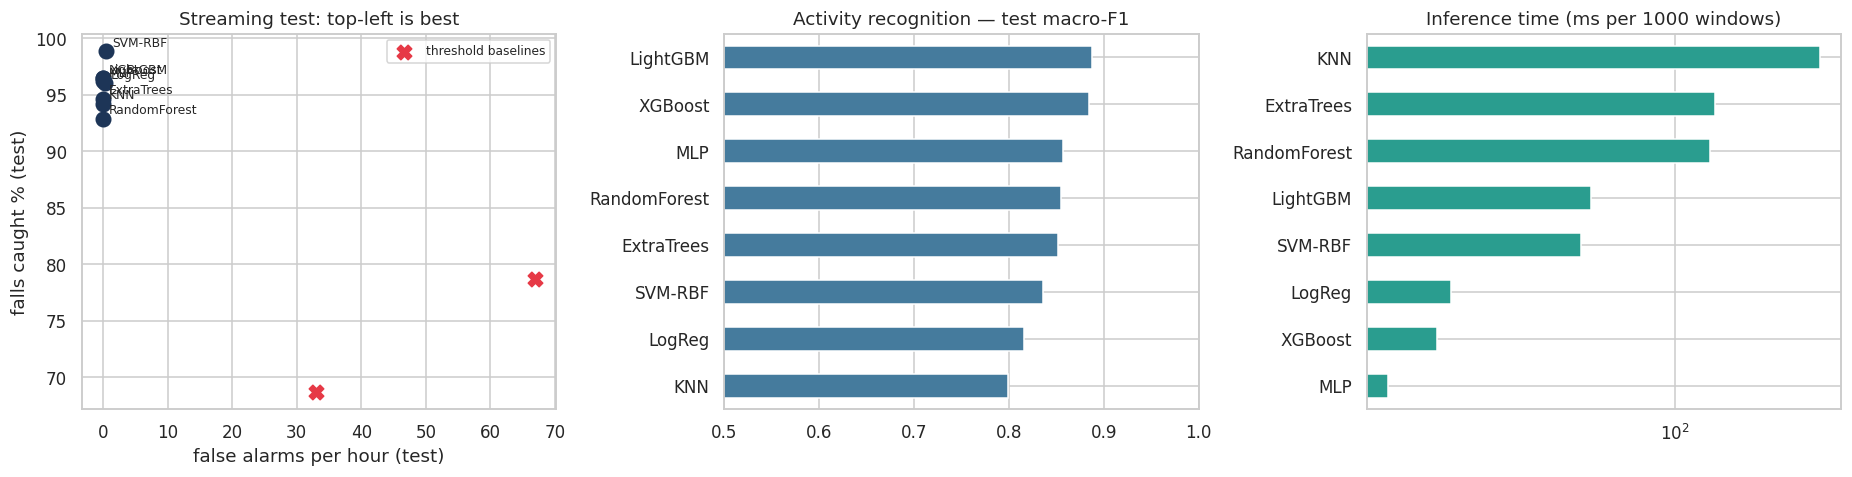

In [8]:
# deployed model = chosen on VALIDATION (sensitivity at the FA target, then fewer false alarms, then speed)
arena['_key'] = list(zip(arena.val_fa_h <= FA_TARGET, arena.val_sens, -arena.val_fa_h, arena.act_val_f1))
BEST_FALL = arena.sort_values('_key', ascending=False).model.iloc[0]
BEST_ACT  = arena.sort_values('act_val_f1', ascending=False).model.iloc[0]
arena = arena.drop(columns='_key')
print('fall model    →', BEST_FALL)
print('activity model →', BEST_ACT)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
a = arena.set_index('model')
bl = baselines[baselines.split == 'test']
ax[0].scatter(a.test_fa_h, a.test_sens * 100, s=90, color='#1d3557')
for n, r in a.iterrows(): ax[0].annotate(n, (r.test_fa_h, r.test_sens * 100), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax[0].scatter(bl.fa_per_hour, bl.sensitivity * 100, s=90, marker='X', color='#e63946', label='threshold baselines')
ax[0].set_xlabel('false alarms per hour (test)'); ax[0].set_ylabel('falls caught % (test)')
ax[0].set_title('Streaming test: top-left is best'); ax[0].legend(fontsize=8)
a.act_test_f1.sort_values().plot.barh(ax=ax[1], color='#457b9d'); ax[1].set_title('Activity recognition — test macro-F1'); ax[1].set_xlim(0.5, 1)
a.ms_per_1000_windows.sort_values().plot.barh(ax=ax[2], color='#2a9d8f'); ax[2].set_title('Inference time (ms per 1000 windows)'); ax[2].set_xscale('log')
for x in ax[1:]: x.set_ylabel('')
plt.tight_layout(); save_fig('30_model_arena'); plt.show()

## 6 · Feature-set comparison (best model on each set)

In [9]:
fs_rows = []
for fset in FEATURE_SETS:
    mf = get_model(BEST_FALL, 'fall', fset); ma = get_model(BEST_ACT, 'activity', fset)
    pv, pt = stream_probs(mf, fset, 'val'), stream_probs(mf, fset, 'test')
    tuned = tune_threshold(pv); ts = ST['test'].evaluate(pt, tuned['thr'], tuned['k'])
    ia, ya = task_data('test', 'activity')
    fs_rows.append(dict(feature_set=fset, n=len(FEATURE_SETS[fset]), test_sens=ts['sensitivity'], test_fa_h=ts['fa_per_hour'],
                        act_test_f1=f1_score(ya, ma.predict(F[FEATURE_SETS[fset]].values[ia]), average='macro')))
fs_cmp = pd.DataFrame(fs_rows); fs_cmp.round(4)

   fitted fall/all_340/MLP on 60000 windows in 19s
   fitted activity/all_340/LightGBM on 65666 windows in 464s
   fitted fall/sel_all/MLP on 60000 windows in 36s
   fitted activity/sel_all/LightGBM on 65666 windows in 167s


,feature_set,n,test_sens,test_fa_h,act_test_f1
0,all_340,340,0.9800,0.0000,0.9033
1,sel_all,120,0.9644,0.2622,0.8895
2,phone,120,0.9622,0.0000,0.8876


## 7 · Final model — full test report

In [10]:
mf = get_model(BEST_FALL, 'fall', 'phone'); ma = get_model(BEST_ACT, 'activity', 'phone')
pv, pt = PV[BEST_FALL]
FALL_CFG = tune_threshold(pv)
res, per = ST['test'].evaluate(pt, FALL_CFG['thr'], FALL_CFG['k'], detail=True)

# 95% bootstrap CI over recordings
boot = []
falls, adls = per[per.type == 'Fall'], per[per.type == 'ADL']
hrs = meta.loc[adls.tid, 'duration_s'].values / 3600
for _ in range(1000):
    f = falls.sample(len(falls), replace=True, random_state=int(rng.integers(1e9)))
    j = rng.integers(0, len(adls), len(adls))
    boot.append((f.detected.mean(), adls.n_alarms.values[j].sum() / hrs[j].sum()))
boot = np.array(boot)
ci = lambda v: f'[{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]'
print(f"Fall model: {BEST_FALL} (phone-ready, {len(FEATURE_SETS['phone'])} features) | threshold {FALL_CFG['thr']:.2f}, {FALL_CFG['k']} window(s)")
print(f"  falls caught      {res['sensitivity']:.3f}  95% CI {ci(boot[:,0])}   ({res['falls']} falls)")
print(f"  false alarms/hour {res['fa_per_hour']:.3f}  95% CI {ci(boot[:,1])}   ({res['adl_hours']:.1f} h of daily activity)")
print(f"  median delay      {res['median_delay']:.2f} s after impact")
for age, g in per.groupby('age'):
    fg, ag = g[g.type == 'Fall'], g[g.type == 'ADL']
    h = meta.loc[ag.tid, 'duration_s'].sum() / 3600
    print(f"  {age:8s}: caught {fg.detected.mean() if len(fg) else float('nan'):.3f} ({len(fg)} falls) | "
          f"FA/h {ag.n_alarms.sum() / max(h, 1e-9):.3f} ({h:.1f} h)")

Fall model: MLP (phone-ready, 120 features) | threshold 0.95, 2 window(s)
  falls caught      0.962  95% CI [0.944, 0.978]   (450 falls)
  false alarms/hour 0.000  95% CI [0.000, 0.000]   (3.8 h of daily activity)
  median delay      0.82 s after impact
  elderly : caught 0.867 (75 falls) | FA/h 0.000 (1.7 h)
  young   : caught 0.981 (375 falls) | FA/h 0.000 (2.1 h)


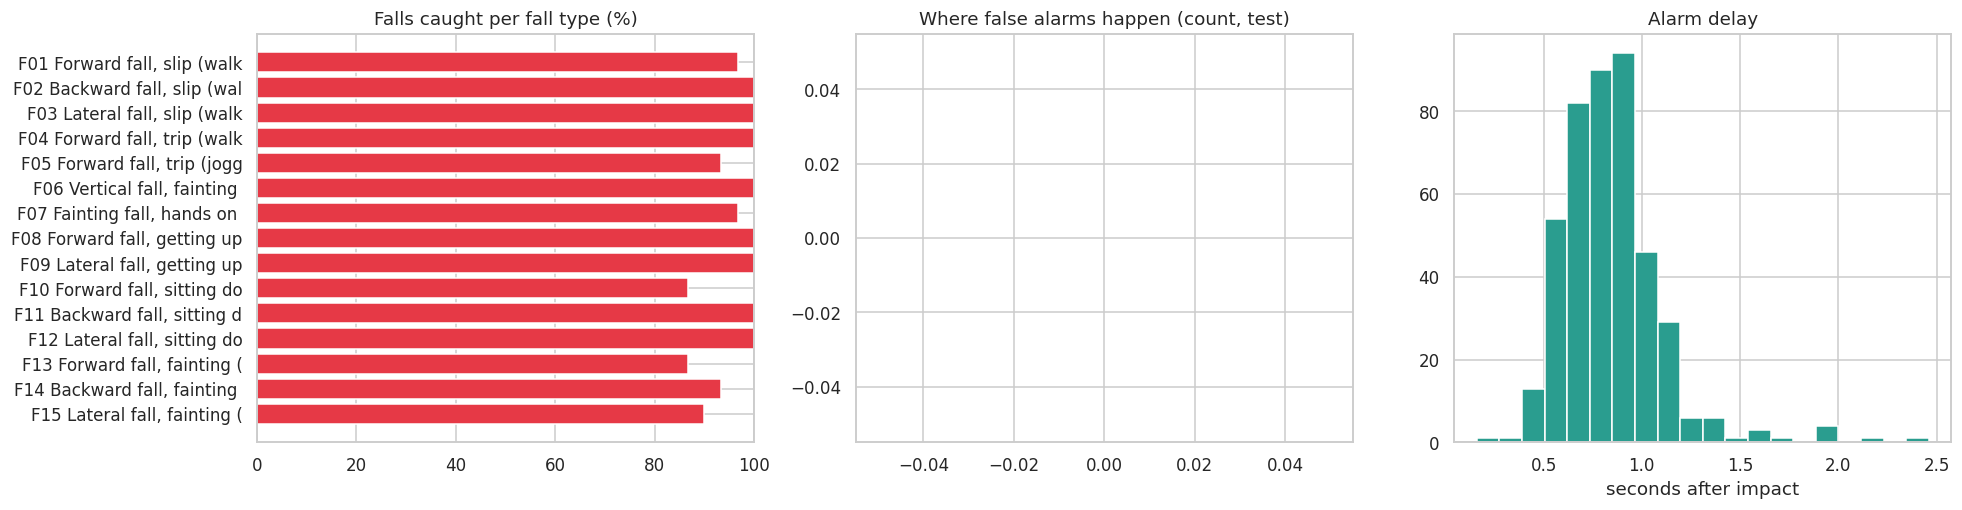

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
code_name = meta.drop_duplicates('code').set_index('code').name
fr = per[per.type == 'Fall'].groupby('code').detected.mean().mul(100)
ax[0].barh([f'{c} {code_name[c][:24]}' for c in fr.index[::-1]], fr.values[::-1], color='#e63946')
ax[0].set_xlim(0, 100); ax[0].set_title('Falls caught per fall type (%)')
fa = per[per.type == 'ADL'].groupby('code').n_alarms.sum()
fa = fa[fa > 0].sort_values()
ax[1].barh([f'{c} {code_name[c][:24]}' for c in fa.index], fa.values, color='#1d3557')
ax[1].set_title('Where false alarms happen (count, test)')
ax[2].hist(per.delay.dropna(), bins=20, color='#2a9d8f'); ax[2].set_xlabel('seconds after impact')
ax[2].set_title('Alarm delay')
plt.tight_layout(); save_fig('31_final_stream_breakdown'); plt.show()

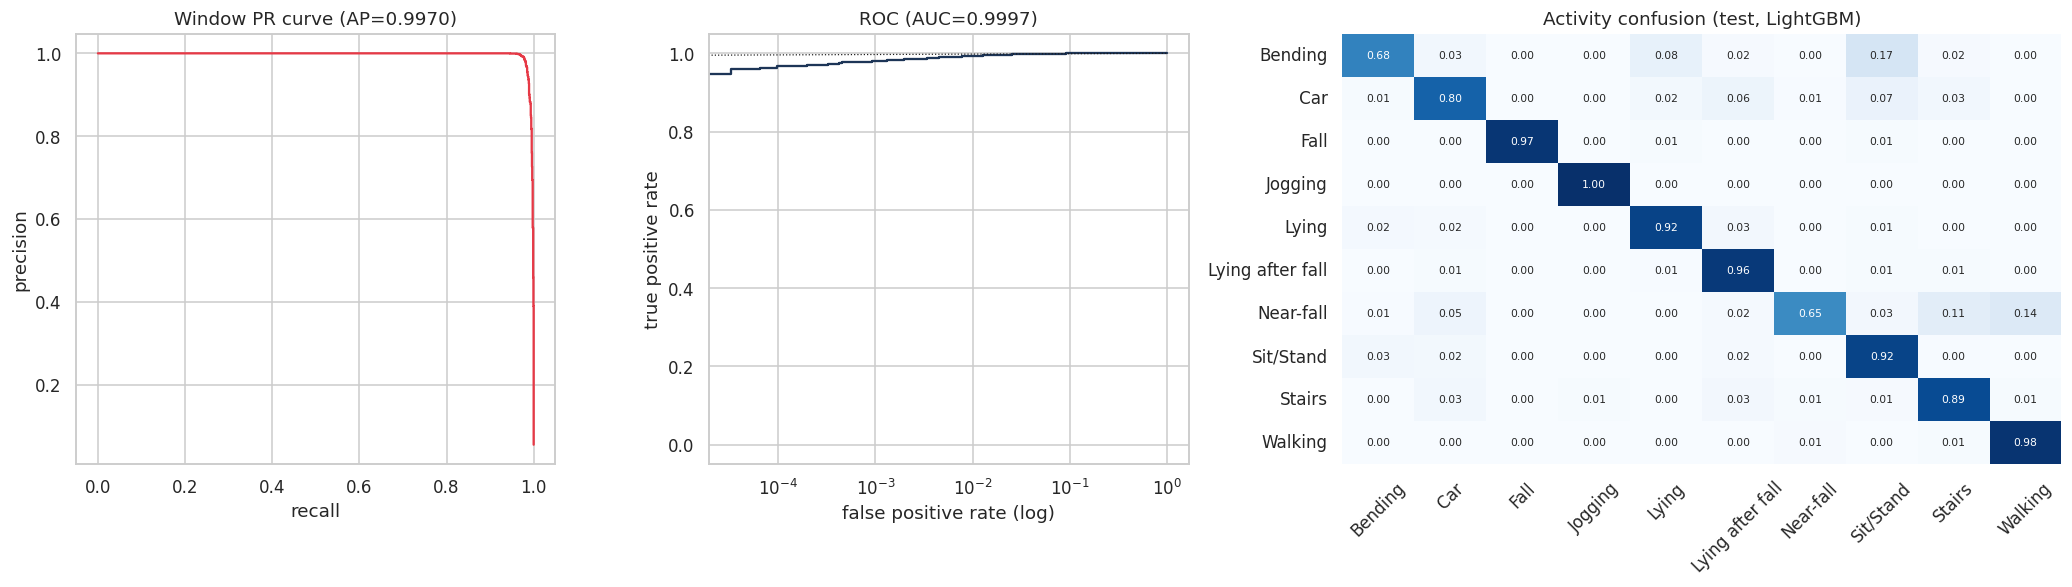

                  precision    recall  f1-score   support

         Bending      0.834     0.682     0.751      1898
             Car      0.817     0.802     0.810      2475
            Fall      0.989     0.969     0.979      1800
         Jogging      0.991     0.996     0.994      3702
           Lying      0.890     0.923     0.906      2470
Lying after fall      0.916     0.959     0.937      5203
       Near-fall      0.881     0.649     0.747      1140
       Sit/Stand      0.866     0.919     0.892      4750
          Stairs      0.899     0.893     0.896      3554
         Walking      0.952     0.978     0.965      3900

        accuracy                          0.909     30892
       macro avg      0.904     0.877     0.888     30892
    weighted avg      0.908     0.909     0.907     30892



In [12]:
it, yt = task_data('test', 'fall')
pw = mf.predict_proba(F[FEATURE_SETS['phone']].values[it])[:, 1]
ia, ya = task_data('test', 'activity')
pa = ma.predict(F[FEATURE_SETS['phone']].values[ia])
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={'width_ratios': [1, 1, 1.5]})
pr, rc, _ = precision_recall_curve(yt, pw); fpr, tpr, _ = roc_curve(yt, pw)
ax[0].plot(rc, pr, color='#e63946'); ax[0].set_xlabel('recall'); ax[0].set_ylabel('precision')
ax[0].set_title(f'Window PR curve (AP={average_precision_score(yt, pw):.4f})')
ax[1].plot(fpr, tpr, color='#1d3557'); ax[1].plot([0, 1], [0, 1], 'k:', lw=0.8); ax[1].set_xscale('log')
ax[1].set_xlabel('false positive rate (log)'); ax[1].set_ylabel('true positive rate'); ax[1].set_title(f'ROC (AUC={roc_auc_score(yt, pw):.4f})')
cm = confusion_matrix(ya, pa, normalize='true')
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=ACT_CLASSES, yticklabels=ACT_CLASSES, ax=ax[2], cbar=False, annot_kws={'size': 7})
ax[2].set_title(f'Activity confusion (test, {BEST_ACT})'); ax[2].tick_params(axis='x', rotation=45)
plt.tight_layout(); save_fig('32_final_curves_confusion'); plt.show()
print(classification_report(ya, pa, target_names=ACT_CLASSES, digits=3))

## 8 · Save for the app and the paper

In [13]:
import shutil
deploy = f"{D['models']}/deploy"; os.makedirs(deploy, exist_ok=True)
shutil.copy(f"{MODEL_DIR}/fall__phone__{BEST_FALL}.joblib", f'{deploy}/fall_model.joblib')
shutil.copy(f"{MODEL_DIR}/activity__phone__{BEST_ACT}.joblib", f'{deploy}/activity_model.joblib')
json.dump({'fall_model': BEST_FALL, 'activity_model': BEST_ACT, 'features': FEATURE_SETS['phone'],
           'threshold': FALL_CFG['thr'], 'consecutive_windows': FALL_CFG['k'], 'refractory_s': 10.0,
           'activity_classes': ACT_CLASSES, 'fa_target_per_hour': FA_TARGET,
           'test': {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in res.items()}},
          open(f'{deploy}/deploy_config.json', 'w'), indent=2)

arena.to_csv(f"{D['artifacts']}/model_arena.csv", index=False)
baselines.to_csv(f"{D['artifacts']}/baselines.csv", index=False)
fs_cmp.to_csv(f"{D['artifacts']}/feature_set_comparison.csv", index=False)
per.to_csv(f"{D['artifacts']}/final_stream_per_recording.csv", index=False)
probs = pd.DataFrame({'win_id': ST['test'].win_ids, **{f'p_{n}': PV[n][1] for n in PV}})
probs.to_parquet(f"{D['data']}/test_stream_probs.parquet", index=False)
print('deploy:', sorted(os.listdir(deploy)))
arena[['model', 'test_sens', 'test_fa_h', 'win_prauc', 'act_test_f1']].round(4)

deploy: ['activity_model.joblib', 'deploy_config.json', 'fall_model.joblib']


,model,test_sens,test_fa_h,win_prauc,act_test_f1
5,MLP,0.9622,0.0000,0.9970,0.8569
0,LogReg,0.9600,0.2622,0.9957,0.8161
4,ExtraTrees,0.9467,0.0000,0.9962,0.8519
7,LightGBM,0.9644,0.0000,0.9953,0.8876
1,SVM-RBF,0.9889,0.5244,0.9967,0.8354
2,KNN,0.9422,0.0000,0.9867,0.7994
6,XGBoost,0.9644,0.0000,0.9930,0.8846
3,RandomForest,0.9289,0.0000,0.9938,0.8545
